# 1. Proximity and choice

**Questions.** How long is the walk from home to the nearest service of each category (RQ1, measure M1), and how many are within 5, 10 and 15 minutes (RQ2, M2), for the residents of Barangay 136, Loyola Heights and Oranbo, against Metro Manila?

**Method.**

- **Residents.** Every 2024 census resident, placed in a residential building (`data/work/origins.parquet`); every statistic is weighted by people.
- **Walks.** Along the OpenStreetMap walking network at 4.2 km/h (70 m a minute); homes and services join the network at their nearest node by a straight hop, which counts as walking.
- **Services.** The default layer of `build_services.py`: OpenStreetMap, DepEd and Overture at confidence 0.5 or more, wherever they are, within 2 km of Metro Manila.
- **M1** is the walk to the nearest one; **M2** counts services (duplicate groups) within each time, read at the home's network node.
- `src/03_analyse/walk_times.py` (run by `03_analyse.sh` before this notebook) does the walking; `measures.py` the summaries.

In [1]:
import sys
from pathlib import Path

# The notebooks import their logic from src/: the shared helpers and the analysis functions.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "shared").is_dir())
for folder in ("src/shared", "src/03_analyse"):
    sys.path.insert(0, str(ROOT / folder))

import charts
import measures
import pandas as pd
from common import TABLES
from IPython.display import Image

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
AREAS = measures.STUDY + ["Metro Manila"]

In [2]:
w, b = measures.load()
m = measures.measures_table(w)
m.to_csv(TABLES / "measures.csv", index=False, float_format="%.6g")
print(f"{len(w):,} origins carrying {w.people.sum():,.0f} people")
print(m[(m.measure == "people")].set_index("area").value.round().astype(int).to_string())

1,573,122 origins carrying 14,001,751 people
area
Barangay 136                          1302
Loyola Heights                       21768
Oranbo                                3374
Tondo, other 258 barangays          636640
Quezon City, other barangays       3062502
City of Pasig, other barangays      849676
Metro Manila                      14001751


## M1: the walk to the nearest service

Minutes for the median resident, with P10 and P90.

In [3]:
m[(m.measure == "M1") & m.stat.isin(["median_min", "p10_min", "p90_min"]) & m.area.isin(AREAS)].pivot_table(
    index=["category", "stat"], columns="area", values="value", sort=False
)[AREAS].round(1)

area                                   Barangay 136  Loyola Heights  Oranbo  Metro Manila
category                   stat                                                          
food_retail                median_min           1.7             6.0     3.7           3.8
                           p10_min              0.5             1.6     1.6           1.4
                           p90_min              2.8            12.3     5.3           9.3
palengke                   median_min          13.0             8.8     6.4          10.6
                           p10_min             11.7             3.3     3.2           4.1
                           p90_min             14.5            15.9    11.7          25.3
pharmacy                   median_min           2.3             7.9     4.7           5.4
                           p10_min              1.0             3.2     2.4           2.0
                           p90_min              3.8            14.6    13.3          12.8
primary_care               median_min           2.5             7.3     6.6           5.0
                           p10_min              1.9             2.3     3.2           1.9
                           p90_min              3.4            15.2     8.7          12.0
hospital                   median_min          10.5            17.2    10.8          11.8
                           p10_min              8.8             5.9     4.5           4.5
                           p90_min             12.0            28.7    20.1          27.5
public_elementary          median_min           3.7            20.9     6.7           9.6
                           p10_min              2.4            10.6     3.5           3.7
                           p90_min              5.3            33.6    13.7          24.4
public_high                median_min           4.0            20.6    21.4          13.9
                           p10_min              2.6            11.7    15.7           5.4
                           p90_min              5.5            27.5    31.4          32.8
open_space                 median_min          14.4             6.9     3.9          12.2
                           p10_min             13.0             2.2     0.9           4.0
                           p90_min             15.8            11.7     8.6          24.8
transit                    median_min           2.9             7.8     3.3           4.6
                           p10_min              1.5             1.5     0.9           0.8
                           p90_min              4.2            13.3     6.1          17.2
food_retail_no_convenience median_min           1.8             7.1     6.8           5.8
                           p10_min              0.5             2.5     3.2           2.2
                           p90_min              4.2            14.9    13.6          13.6

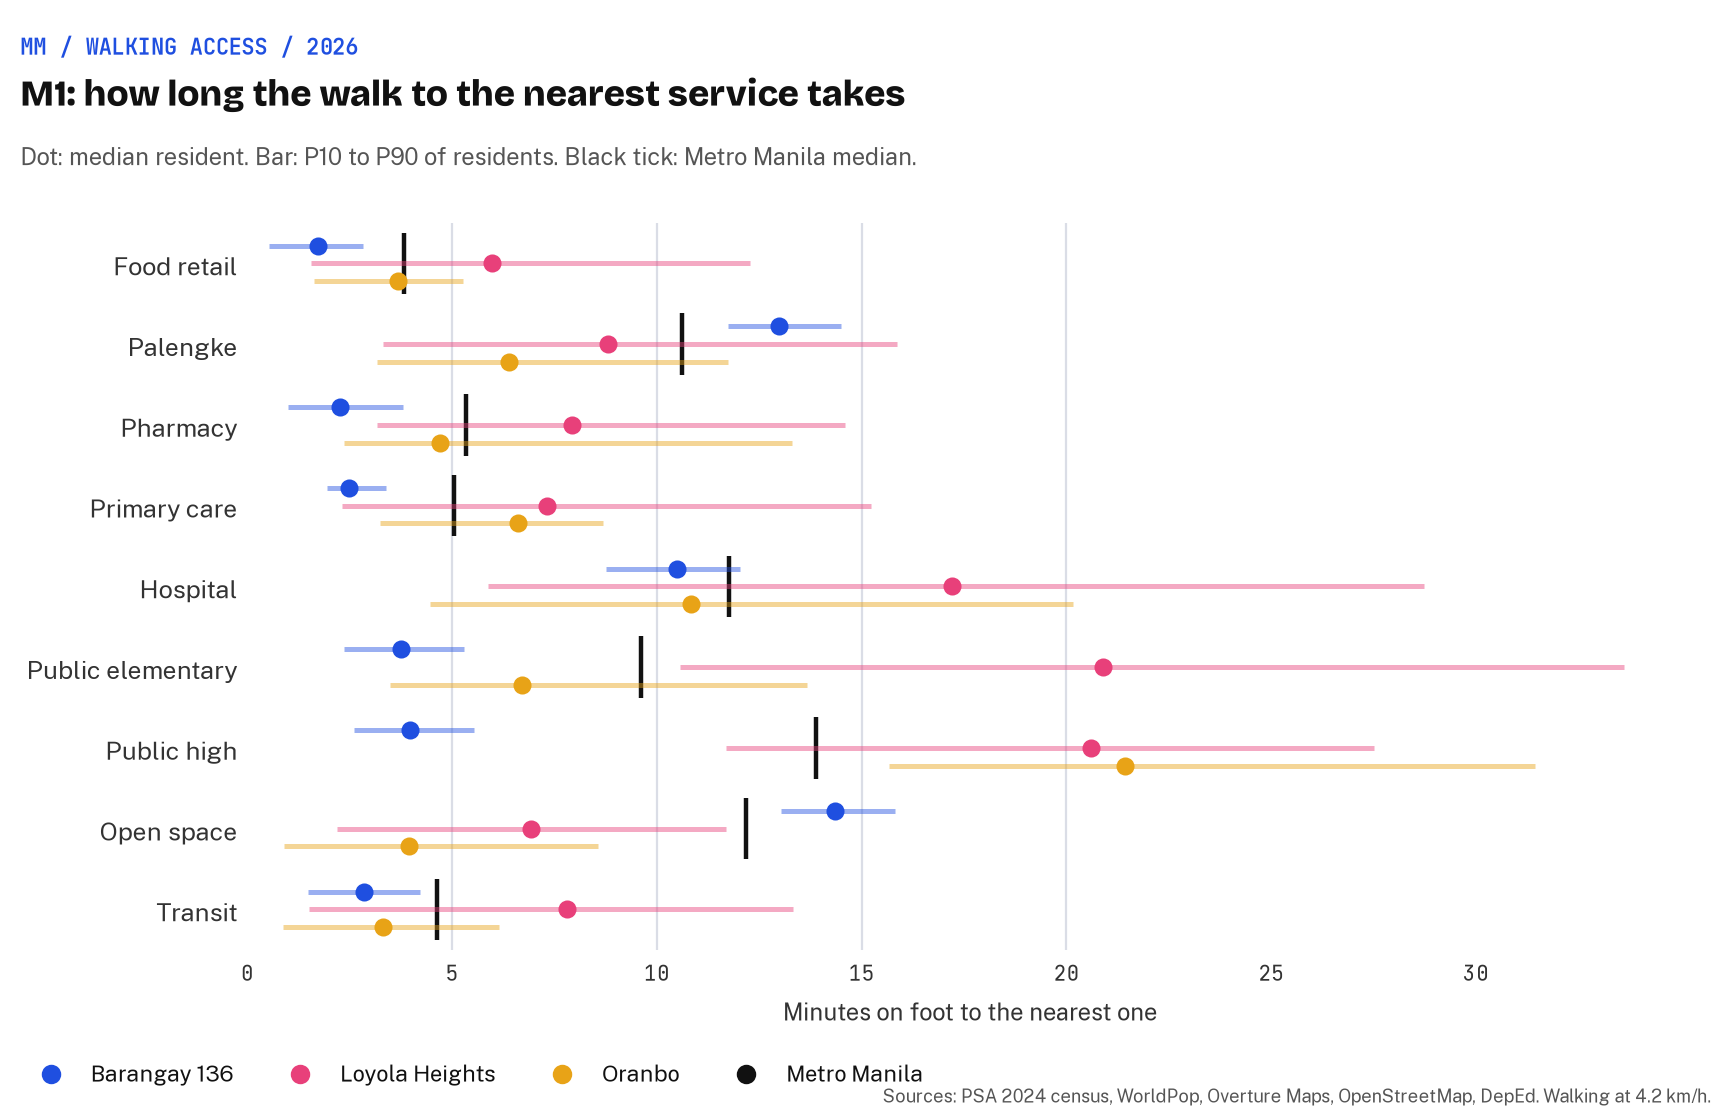

In [4]:
Image(charts.m1_chart(m))

**Reading.** The three barangays differ by category more than overall.

- **Barangay 136** has the shortest median walk of the three to food retail (1.7 minutes), pharmacies (2.3), primary care (2.5), hospitals (10.5), both public school levels (3.7 and 4.0) and transit (2.9), and its spread is narrow because the barangay is one block. Its longest walks are to a palengke (13.0) and open space (14.4).
- **Loyola Heights** has the longest median walk of the three to food, pharmacies, primary care, hospitals (17.2), public elementary (20.9) and transit (7.8), and the widest spread: its P90 resident walks 12 minutes for food and 34 for a public elementary school.
- **Oranbo** is closest to open space (3.9) and a palengke (6.4), but its median resident walks 21.4 minutes to a public high school, the longest of the three.
- Against the Metro Manila median, Barangay 136 and Oranbo are each quicker for seven of the nine categories, Loyola Heights for two (palengke and open space).

## The 10-minute minimum

Share of residents within 10 minutes (700 m) of the nearest service.

In [5]:
m[(m.measure == "M1") & m.stat.isin(["share_within_10min"]) & m.area.isin(AREAS)].pivot_table(
    index=["category", "stat"], columns="area", values="value", sort=False
)[AREAS].round(2)

,area,Barangay 136,Loyola Heights,Oranbo,Metro Manila
category,stat,,,,
food_retail,share_within_10min,1.00,0.83,1.00,0.92
palengke,share_within_10min,0.02,0.63,0.78,0.47
pharmacy,share_within_10min,1.00,0.67,0.82,0.82
primary_care,share_within_10min,1.00,0.68,0.97,0.84
hospital,share_within_10min,0.39,0.28,0.48,0.41
public_elementary,share_within_10min,1.00,0.09,0.73,0.52
public_high,share_within_10min,1.00,0.05,0.00,0.31
open_space,share_within_10min,0.00,0.82,0.97,0.39
transit,share_within_10min,1.00,0.66,1.00,0.76


**Reading.** Every resident of Barangay 136 is within 10 minutes of food, a pharmacy, primary care, both public school levels and transit, but only 2% of a palengke and none of open space. In Oranbo nobody is within 10 minutes of a public high school. Loyola Heights is the only one of the three below the Metro Manila share for food (83% against 92%), and 9% of its residents are within 10 minutes of a public elementary school.

## Food with and without convenience stores

Sari-sari stores are almost unmapped, so convenience stores stand in for much of everyday food buying. Leaving them out shows how much the definition matters.

In [6]:
m[
    (m.measure == "M1")
    & m.category.isin(["food_retail", "food_retail_no_convenience"])
    & m.area.isin(AREAS)
    & m.stat.isin(["median_min", "p90_min", "share_within_10min"])
].pivot_table(index=["category", "stat"], columns="area", values="value", sort=False)[AREAS].round(2)

area                                           Barangay 136  Loyola Heights  Oranbo  Metro Manila
category                   stat                                                                  
food_retail                median_min                  1.72            5.98    3.68          3.82
                           p90_min                     2.82           12.28    5.28          9.31
                           share_within_10min          1.00            0.83    1.00          0.92
food_retail_no_convenience median_min                  1.83            7.14    6.81          5.84
                           p90_min                     4.16           14.85   13.65         13.62
                           share_within_10min          1.00            0.70    0.81          0.79

**Reading.** The definition matters most where convenience stores carry food access. Without them, Oranbo's median walk to food nearly doubles (3.7 to 6.8 minutes) and the share within 10 minutes falls from 100% to 81%; Loyola Heights' median rises from 6.0 to 7.1 minutes; Barangay 136 barely moves (1.7 to 1.8), because a grocery is about as close as a convenience store there. Across Metro Manila the median rises from 3.8 to 5.8 minutes. Neither version counts the unmapped sari-sari stores.

## M2: choice within 5, 10 and 15 minutes

Services within each time of the median resident.

In [7]:
m[
    (m.measure == "M2")
    & m.stat.isin(["median_within_5min", "median_within_10min", "median_within_15min"])
    & m.area.isin(AREAS)
].pivot_table(index=["category", "stat"], columns="area", values="value", sort=False)[AREAS].round(0)

area                                   Barangay 136  Loyola Heights  Oranbo  Metro Manila
category          stat                                                                   
food_retail       median_within_5min            3.0             0.0     1.0           2.0
                  median_within_10min           5.0             7.0    11.0           9.0
                  median_within_15min          11.0            24.0    31.0          21.0
palengke          median_within_5min            0.0             0.0     0.0           0.0
                  median_within_10min           0.0             1.0     1.0           0.0
                  median_within_15min           1.0             2.0     2.0           1.0
pharmacy          median_within_5min            4.0             0.0     1.0           1.0
                  median_within_10min           6.0             2.0     6.0           4.0
                  median_within_15min           9.0             7.0    16.0          10.0
primary_care      median_within_5min            4.0             0.0     0.0           1.0
                  median_within_10min           6.0             1.0     4.0           4.0
                  median_within_15min          10.0             5.0    10.0          11.0
hospital          median_within_5min            0.0             0.0     0.0           0.0
                  median_within_10min           1.0             0.0     0.0           0.0
                  median_within_15min           1.0             0.0     2.0           1.0
public_elementary median_within_5min            0.0             0.0     0.0           0.0
                  median_within_10min           2.0             0.0     1.0           1.0
                  median_within_15min           4.0             0.0     1.0           1.0
public_high       median_within_5min            0.0             0.0     0.0           0.0
                  median_within_10min           1.0             0.0     0.0           0.0
                  median_within_15min           3.0             0.0     0.0           1.0
open_space        median_within_5min            0.0             0.0     1.0           0.0
                  median_within_10min           0.0             1.0     2.0           0.0
                  median_within_15min           1.0             3.0     4.0           1.0
transit           median_within_5min            1.0             0.0     0.0           0.0
                  median_within_10min           5.0             2.0     6.0           4.0
                  median_within_15min          12.0             9.0    14.0          10.0

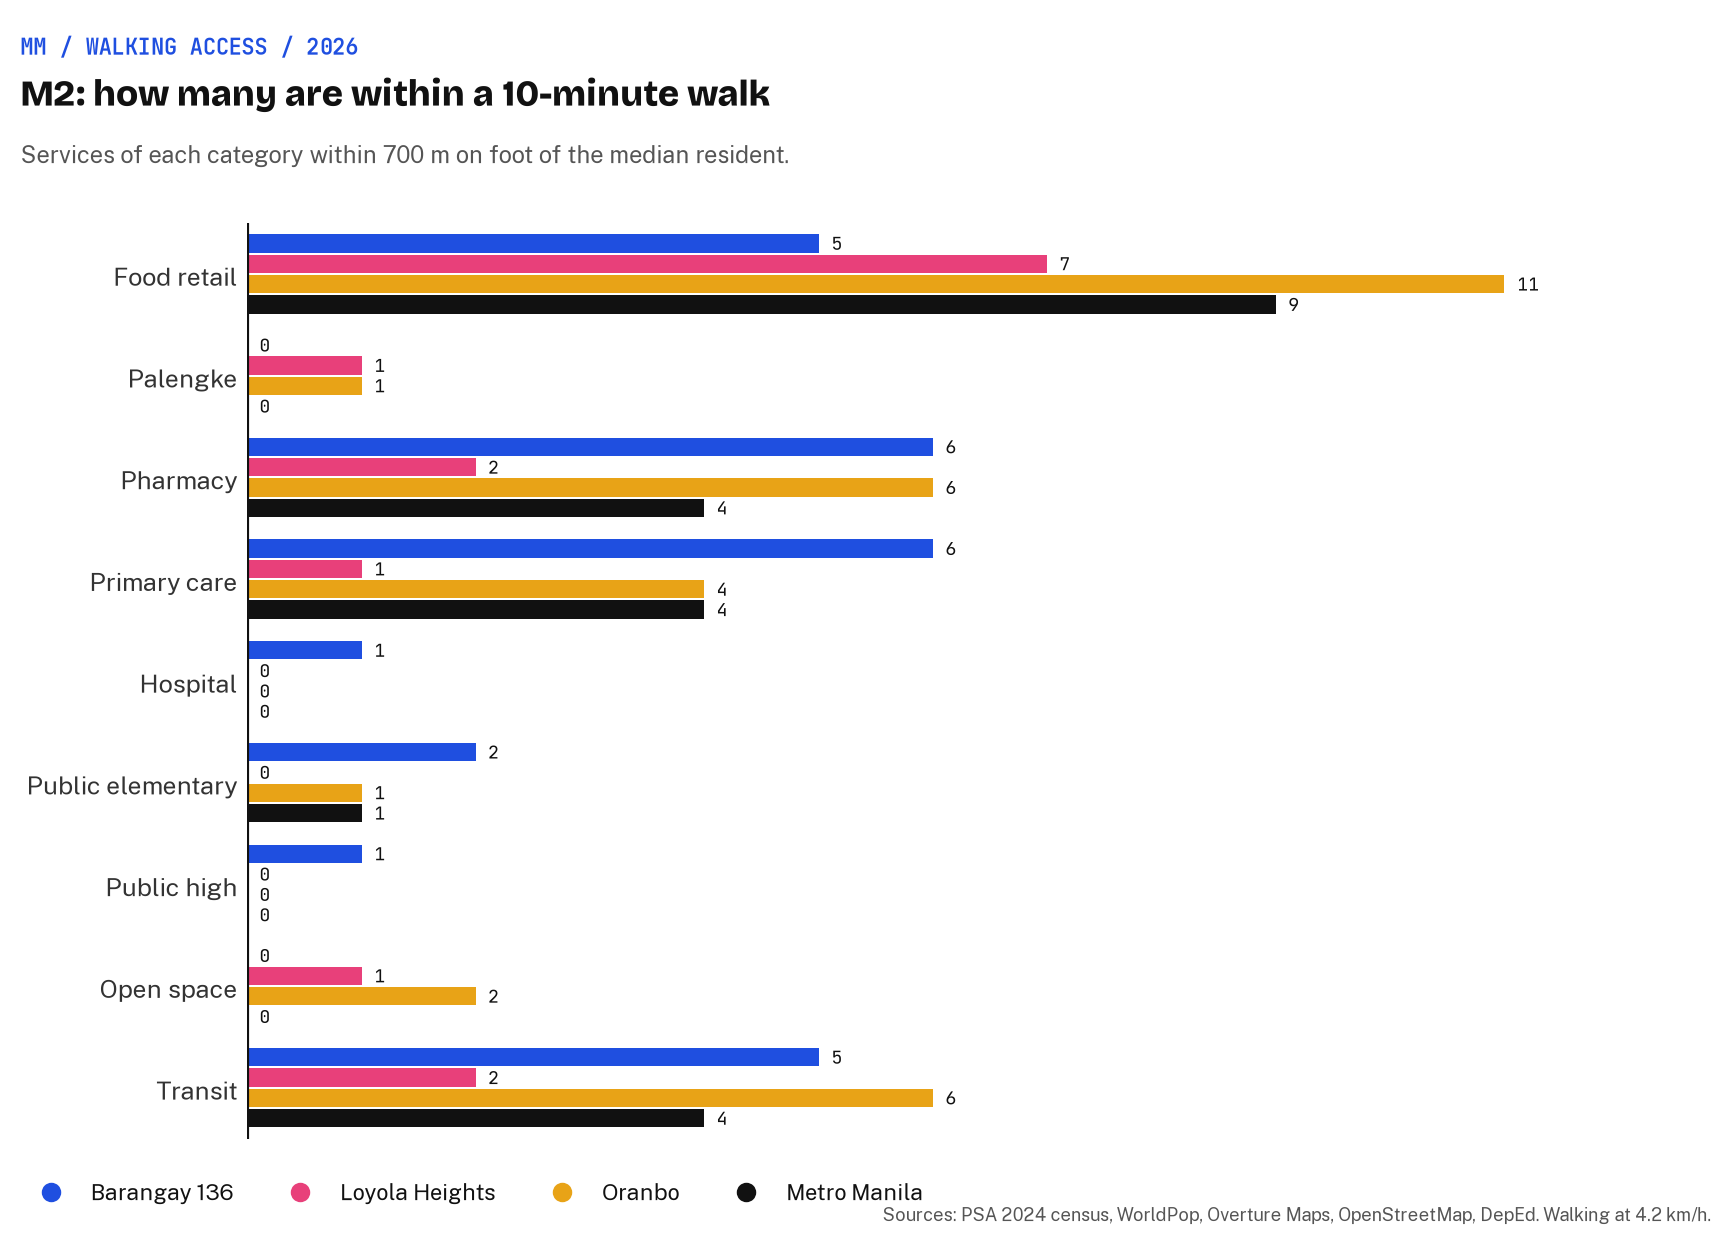

In [8]:
Image(charts.m2_chart(m))

**Reading.** Choice tells the same story with one twist: Barangay 136's median resident has more services within 5 minutes than either of the others (three food shops, four pharmacies, four clinics), but within 15 minutes Oranbo's median resident reaches more food shops (31 against 11), pharmacies, hospitals, open spaces and transit stops. Loyola Heights' median resident has no public school of either level within 15 minutes.